# Online Retail – Mô hình hóa và đánh giá (Phase 4–7)

Notebook này dùng bảng khách hàng và các file kết quả do notebook analysis (Phase 1–3) tạo ra, nên **phải chạy notebook analysis trước**.

Notebook chạy được theo hai cách đặt file: cấu trúc repo (notebook trong `predict/`, dữ liệu trong `../dataset/`) hoặc đặt chung một thư mục với các file dữ liệu, như khi nộp từng file.

## Thiết lập

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.4f}'.format)

In [2]:
# Cùng quy tắc tìm file với notebook analysis: thư mục hiện tại hoặc ../dataset
SEARCH_DIRS = [Path('.'), Path('../dataset')]
MODEL_DATA_FILES = sorted(p for d in SEARCH_DIRS for p in d.glob('Nhom*_Du_lieu_mo_hinh.csv'))
if len(MODEL_DATA_FILES) != 1:
    raise FileNotFoundError(f'Cần đúng một file Nhom*_Du_lieu_mo_hinh.csv trong {[str(d) for d in SEARCH_DIRS]}, '
                            f'tìm thấy {len(MODEL_DATA_FILES)}.')
MODEL_DATA_PATH = MODEL_DATA_FILES[0]
DATA_DIR = MODEL_DATA_PATH.parent
GROUP_PREFIX = MODEL_DATA_PATH.stem.removesuffix('_Du_lieu_mo_hinh')
OUT_DIR = DATA_DIR / f'{GROUP_PREFIX}_Ket_qua'
FIG_DIR = OUT_DIR / 'figures'

# Các file chỉ có sau khi chạy notebook analysis; kiểm tra sớm để báo lỗi rõ ràng
REQUIRED_INPUTS = [OUT_DIR / 'analysis_summary.json', OUT_DIR / 'customers_keep_duplicates.csv']
missing_inputs = [str(p) for p in REQUIRED_INPUTS if not p.exists()]
if missing_inputs:
    raise FileNotFoundError(f'Thiếu {missing_inputs}; hãy chạy notebook analysis trước.')

TARGET = 'FutureSpend'
FEATURES = ['Monetary', 'Frequency', 'Recency', 'Tenure', 'Products', 'IsUK']
SLR_FEATURE = 'Monetary'   # định trước theo nghiệp vụ, không chọn theo test
RANDOM_STATE = 42
TEST_SIZE = 0.30
N_SPLITS = 5
N_JOBS = -1

CV = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'mse': 'neg_mean_squared_error', 'r2': 'r2'}
RIDGE_GRID = {'poly__degree': [1, 2, 3], 'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]}

MAIN_COLOR = '#146482'
ACCENT_COLOR = '#b45538'
MUTED_COLOR = '#8997a1'

In [3]:
def save_fig(fig, name):
    """Lưu hình vào thư mục figures để báo cáo và slide dùng lại."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

## Nạp dữ liệu và chia train/test

In [4]:
customers = pd.read_csv(MODEL_DATA_PATH, index_col='CustomerID', dtype={'CustomerID': 'string'})
X = customers[FEATURES]
y = customers[TARGET]

# Tái tạo đúng phép chia của notebook analysis (cùng thứ tự dòng, test_size và random_state)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert (customers.loc[X_train.index, 'Split'] == 'train').all()
assert (customers.loc[X_test.index, 'Split'] == 'test').all()
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print('Đặc trưng:', FEATURES)

Train: (1901, 6) | Test: (815, 6)
Đặc trưng: ['Monetary', 'Frequency', 'Recency', 'Tenure', 'Products', 'IsUK']


# Phase 4. Chuẩn bị dữ liệu cho mô hình (chỉ dùng tập train)
## Step 7. Thông tin trùng lặp giữa các đặc trưng

Sáu đặc trưng được định nghĩa trước EDA và được giữ nguyên cho MLR; bước này chỉ để hiểu đa cộng tuyến khi diễn giải hệ số, không loại biến theo kết quả.

In [5]:
feature_corr = X_train.corr()
upper = np.triu(np.ones(feature_corr.shape, dtype=bool), k=1)
feature_pairs = (feature_corr.where(upper).stack().rename('pearson_r').to_frame()
                 .sort_values('pearson_r', key=np.abs, ascending=False))
feature_pairs.head(6)

pearson_r
Frequency Products      0.6779
Monetary  Frequency     0.5017
          Products      0.3798
Recency   Tenure        0.3777
Frequency Tenure        0.3420
          Recency      -0.3257

## Step 8. Pipeline cho từng mô hình

`StandardScaler` (và `PolynomialFeatures`) nằm **trong Pipeline**, nên khi kiểm chứng chéo chúng chỉ được fit trên phần train của từng fold. SLR dùng trực tiếp `Monetary` theo GBP để hệ số đọc được theo đơn vị gốc.

In [6]:
def poly_pipeline(degree):
    return Pipeline([('scale', StandardScaler()),
                     ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
                     ('model', LinearRegression())])

MODELS = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'SLR Monetary': Pipeline([('select', ColumnTransformer([('slr', 'passthrough', [SLR_FEATURE])])),
                              ('model', LinearRegression())]),
    'MLR': Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]),
    'Polynomial 2': poly_pipeline(2),
    'Polynomial 3': poly_pipeline(3),
}
MODELS['SLR Monetary']

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('select', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('slr', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matric

# Phase 5. Mô hình hóa
## Step 9. Tìm tham số Ridge (GridSearchCV trên train)

Lưới gồm 3 bậc đa thức × 6 giá trị alpha = 18 tổ hợp, chấm bằng MSE âm trên 5 fold của train. MSE âm chỉ là quy ước của sklearn (điểm lớn hơn là tốt hơn); bảng dưới đổi dấu rồi lấy căn để có CV RMSE.

In [7]:
ridge_pipe = Pipeline([('scale', StandardScaler()),
                       ('poly', PolynomialFeatures(include_bias=False)),
                       ('ridge', Ridge())])
grid = GridSearchCV(ridge_pipe, RIDGE_GRID, cv=CV, scoring='neg_mean_squared_error',
                    refit=True, n_jobs=N_JOBS, error_score='raise')
grid.fit(X_train, y_train)
MODELS['Ridge grid'] = grid.best_estimator_
print('Tham số Ridge chọn trên train:', grid.best_params_)

cv_grid = pd.DataFrame(grid.cv_results_)
cv_grid['CV_RMSE_GBP'] = np.sqrt(-cv_grid['mean_test_score'])
cv_grid[['param_poly__degree', 'param_ridge__alpha', 'CV_RMSE_GBP', 'rank_test_score']].to_csv(
    OUT_DIR / 'ridge_grid.csv', index=False)
cv_grid.pivot_table(index='param_poly__degree', columns='param_ridge__alpha', values='CV_RMSE_GBP')

Tham số Ridge chọn trên train: {'poly__degree': 1, 'ridge__alpha': 100}


param_ridge__alpha,0.0100,0.1000,1.0000,10.0000,100.0000,"1,000.0000"
param_poly__degree,,,,,,
1,"1,721.1389","1,721.1004","1,720.7164","1,717.0434","1,693.9713","1,832.1864"
2,"3,888.3853","3,886.5612","3,868.4329","3,707.4735","3,073.6125","2,532.0575"
3,"15,414.4859","14,702.8593","11,078.5909","8,737.8379","8,040.4266","8,415.9837"


## Step 10. So sánh và khóa mô hình bằng CV

CV_RMSE = căn của **MSE trung bình** 5 fold (không phải trung bình 5 RMSE); CV_R2 là trung bình R² từng fold. Đây là điểm dùng để chọn mô hình, không phải ước lượng hiệu suất cuối cùng. Tập test chỉ được mở sau khi mô hình đã khóa.

In [8]:
selection_rows = []
for name, model in MODELS.items():
    cv_res = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, error_score='raise')
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    selection_rows.append({'model': name,
                           'CV_RMSE_GBP': np.sqrt(-cv_res['test_mse'].mean()),
                           'CV_R2_mean': cv_res['test_r2'].mean(),
                           'CV_R2_std': cv_res['test_r2'].std(),
                           'train_R2': r2_score(y_train, train_pred),
                           'train_RMSE_GBP': np.sqrt(mean_squared_error(y_train, train_pred))})
selection = pd.DataFrame(selection_rows).sort_values('CV_RMSE_GBP').reset_index(drop=True)
selection.to_csv(OUT_DIR / 'model_selection.csv', index=False)
selection

,model,CV_RMSE_GBP,CV_R2_mean,CV_R2_std,train_R2,train_RMSE_GBP
0,SLR Monetary,"1,666.3256",0.6672,0.2713,0.6899,"1,569.7454"
1,Ridge grid,"1,693.9713",0.6517,0.2422,0.6950,"1,556.6847"
2,MLR,"1,721.1432",0.6465,0.2785,0.6969,"1,551.8978"
3,Mean baseline,"2,820.5297",-0.0145,0.0278,0.0000,"2,818.9142"
4,Polynomial 2,"3,888.5881",-0.6048,1.1442,0.8696,"1,018.0660"
5,Polynomial 3,"15,501.5787",-19.9418,36.0741,0.9670,512.1467


In [9]:
# Chọn mô hình có CV RMSE thấp nhất; không đổi lựa chọn sau khi xem test
BEST_NAME = selection.loc[0, 'model']
best_model = MODELS[BEST_NAME]
print('Mô hình khóa trước khi đánh giá test:', BEST_NAME)

Mô hình khóa trước khi đánh giá test: SLR Monetary


Đa thức bậc 3 có R² train rất cao nhưng CV R² âm mạnh: đây là **quá khớp** (overfitting). Thêm biến hoặc tăng bậc làm fit train tốt hơn nhưng không cải thiện sai số khái quát.

# Phase 6. Đánh giá mô hình trên tập test
## Step 11. Chỉ số trên tập test

MSE có đơn vị GBP², không bị giới hạn trong [0, 1]; R² có thể âm và không phải tỷ lệ khách dự đoán đúng. Bảng test của các mô hình khác chỉ để mô tả, không dùng để chọn lại mô hình.

In [10]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE_GBP2': mse, 'RMSE_GBP': np.sqrt(mse),
            'MAE_GBP': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred),
            'median_AE_GBP': np.median(np.abs(np.asarray(y_true) - y_pred)),
            'negative_predictions': int(np.sum(y_pred < 0))}

test_rows = [{'model': name, **metrics(y_test, model.predict(X_test))} for name, model in MODELS.items()]
test_metrics = pd.DataFrame(test_rows)
test_metrics.to_csv(OUT_DIR / 'test_metrics.csv', index=False)
test_metrics

,model,MSE_GBP2,RMSE_GBP,MAE_GBP,R2,median_AE_GBP,negative_predictions
0,Mean baseline,"6,521,903.3836","2,553.8018",779.3521,-0.0027,533.3173,0
1,SLR Monetary,"3,442,366.8759","1,855.3617",492.9188,0.4707,175.4620,146
2,MLR,"3,558,747.2664","1,886.4642",529.4930,0.4529,194.8595,190
3,Polynomial 2,"3,930,723.1317","1,982.6051",552.4433,0.3957,182.0756,48
4,Polynomial 3,"24,080,519.8835","4,907.1906",798.9648,-2.7023,181.1088,45
5,Ridge grid,"3,606,957.1950","1,899.1991",530.0032,0.4454,196.0867,196


In [11]:
y_hat = best_model.predict(X_test)
predictions = pd.DataFrame({'CustomerID': X_test.index, 'actual_GBP': y_test.values,
                            'predicted_GBP': y_hat, 'predicted_nonnegative_GBP': np.maximum(0, y_hat)})
predictions['residual_GBP'] = predictions['actual_GBP'] - predictions['predicted_GBP']
predictions['absolute_error_GBP'] = predictions['residual_GBP'].abs()
predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False)

baseline_rmse = test_metrics.set_index('model').loc['Mean baseline', 'RMSE_GBP']
best_rmse = test_metrics.set_index('model').loc[BEST_NAME, 'RMSE_GBP']
rmse_gain = 100 * (1 - best_rmse / baseline_rmse)
print(f'{BEST_NAME} giảm RMSE {rmse_gain:.2f}% so với baseline trung bình')

# Chặn dự đoán âm tại 0 chỉ là hậu xử lý, công bố riêng; bảng chính giữ dự đoán gốc
clipped_metrics = metrics(y_test, np.maximum(0, y_hat))
pd.DataFrame({'original': metrics(y_test, y_hat), 'clipped_at_0': clipped_metrics})

SLR Monetary giảm RMSE 27.35% so với baseline trung bình


,original,clipped_at_0
MSE_GBP2,"3,442,366.8759","3,441,427.8588"
RMSE_GBP,"1,855.3617","1,855.1086"
MAE_GBP,492.9188,486.9770
R2,0.4707,0.4709
median_AE_GBP,175.4620,173.0075
negative_predictions,146.0000,0.0000


In [12]:
# Sai số lớn nhất: không loại khỏi test
error_sorted = predictions.sort_values('absolute_error_GBP', ascending=False)
top5_sse_share = (error_sorted.head(5)['residual_GBP'].pow(2).sum()
                  / predictions['residual_GBP'].pow(2).sum())
print(f'Năm sai số lớn nhất chiếm {top5_sse_share:.2%} tổng bình phương sai số (SSE)')
error_sorted.head(10)

Năm sai số lớn nhất chiếm 83.31% tổng bình phương sai số (SSE)


,CustomerID,actual_GBP,predicted_GBP,predicted_nonnegative_GBP,residual_GBP,absolute_error_GBP
756,17949,"36,266.8000","4,653.4554","4,653.4554","31,613.3446","31,613.3446"
62,12931,"28,610.0000","1,958.5403","1,958.5403","26,651.4597","26,651.4597"
476,14156,"40,885.1200","22,844.7911","22,844.7911","18,040.3289","18,040.3289"
619,14088,"17,962.9800","3,859.4255","3,859.4255","14,103.5545","14,103.5545"
671,15061,"5,852.0800","16,016.2093","16,016.2093","-10,164.1293","10,164.1293"
396,17706,"7,138.6500",368.3457,368.3457,"6,770.3043","6,770.3043"
311,16180,"7,508.7500","1,342.1153","1,342.1153","6,166.6347","6,166.6347"
774,13798,"5,773.7200","11,594.4945","11,594.4945","-5,820.7745","5,820.7745"
371,17841,"10,734.4900","5,915.1369","5,915.1369","4,819.3531","4,819.3531"
342,12590,0.0000,"4,801.6047","4,801.6047","-4,801.6047","4,801.6047"


## Step 12. Biểu đồ chẩn đoán

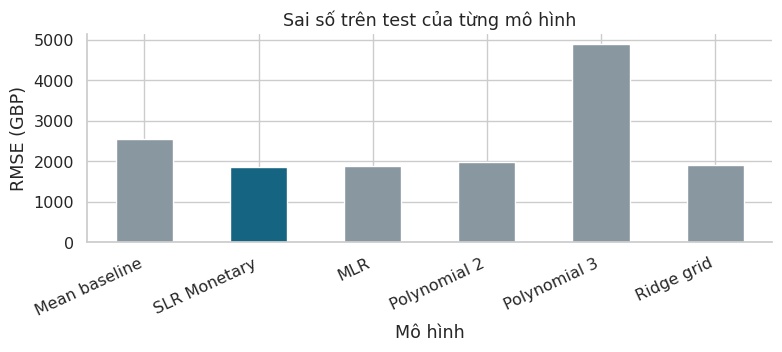

In [13]:
test_rmse = test_metrics.set_index('model')['RMSE_GBP']
bar_colors = [MAIN_COLOR if name == BEST_NAME else MUTED_COLOR for name in test_rmse.index]
fig, ax = plt.subplots(figsize=(8, 3.7))
test_rmse.plot.bar(ax=ax, color=bar_colors)
ax.set(title='Sai số trên test của từng mô hình', xlabel='Mô hình', ylabel='RMSE (GBP)')
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
save_fig(fig, '05_model_comparison')

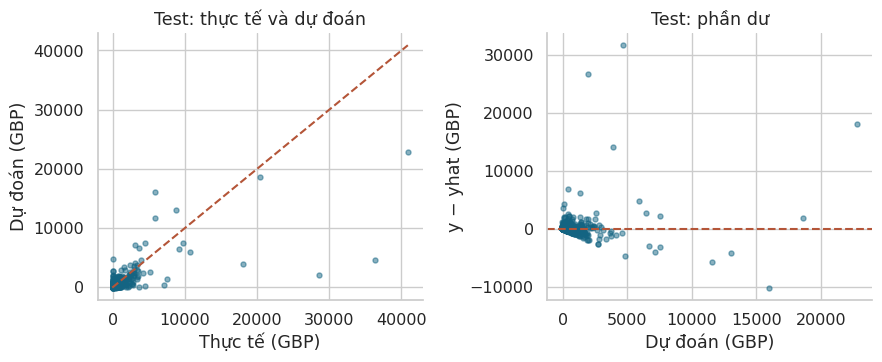

In [14]:
lo = min(0, float(y_hat.min()))
hi = max(float(y_test.max()), float(y_hat.max()))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].scatter(y_test, y_hat, s=13, alpha=0.5, color=MAIN_COLOR)
axes[0].plot([lo, hi], [lo, hi], '--', color=ACCENT_COLOR)
axes[0].set(xlabel='Thực tế (GBP)', ylabel='Dự đoán (GBP)', title='Test: thực tế và dự đoán')
axes[1].scatter(y_hat, y_test.values - y_hat, s=13, alpha=0.5, color=MAIN_COLOR)
axes[1].axhline(0, color=ACCENT_COLOR, linestyle='--')
axes[1].set(xlabel='Dự đoán (GBP)', ylabel='y − yhat (GBP)', title='Test: phần dư')
save_fig(fig, '06_diagnostics')

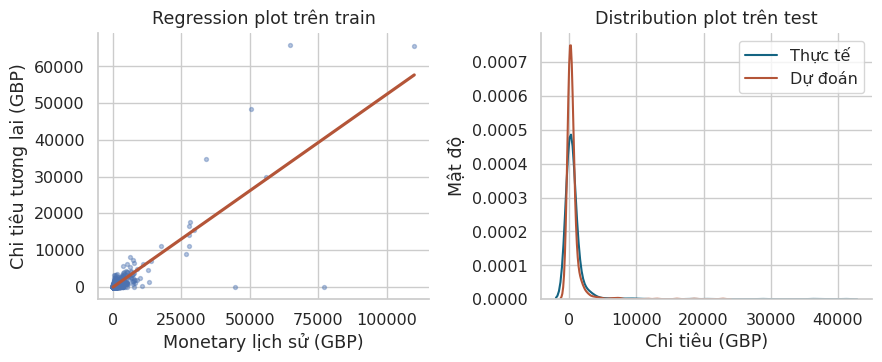

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
sns.regplot(x=X_train[SLR_FEATURE], y=y_train, ax=axes[0], scatter_kws={'s': 8, 'alpha': 0.4},
            line_kws={'color': ACCENT_COLOR}, ci=None)
axes[0].set(xlabel='Monetary lịch sử (GBP)', ylabel='Chi tiêu tương lai (GBP)', title='Regression plot trên train')
sns.kdeplot(y_test, ax=axes[1], label='Thực tế', color=MAIN_COLOR)
sns.kdeplot(y_hat, ax=axes[1], label='Dự đoán', color=ACCENT_COLOR)
axes[1].set(xlabel='Chi tiêu (GBP)', ylabel='Mật độ', title='Distribution plot trên test')
axes[1].legend()
save_fig(fig, '07_regression_distribution')

Chia ngẫu nhiên theo mã khách đánh giá khách chưa dùng để fit trong **cùng kỳ**; kết quả chưa chứng minh mô hình tốt cho quý khác.

# Phase 7. Diễn giải, kiểm tra độ nhạy và demo
## Step 13. Hệ số mô hình

Hệ số MLR được đổi từ thang chuẩn hóa về đơn vị gốc của từng đặc trưng; đây là liên hệ có điều kiện, không phải tác động nhân quả.

In [16]:
slr = MODELS['SLR Monetary'].named_steps['model']
print(f'SLR: {TARGET} = {slr.intercept_:,.4f} + {slr.coef_[0]:.6f} * {SLR_FEATURE}')

mlr_scale = MODELS['MLR'].named_steps['scale']
mlr_model = MODELS['MLR'].named_steps['model']
mlr_coef_original = mlr_model.coef_ / mlr_scale.scale_
mlr_intercept_original = mlr_model.intercept_ - np.dot(mlr_coef_original, mlr_scale.mean_)
print(f'MLR intercept theo đơn vị gốc: {mlr_intercept_original:,.4f}')
pd.DataFrame({'coef_scaled': mlr_model.coef_, 'coef_original_unit': mlr_coef_original}, index=FEATURES)

SLR: FutureSpend = -97.8529 + 0.524496 * Monetary
MLR intercept theo đơn vị gốc: 139.3578


,coef_scaled,coef_original_unit
Monetary,"2,227.5541",0.4990
Frequency,250.0089,68.0182
Recency,139.1596,2.6302
Tenure,-189.8147,-3.4626
Products,80.7906,1.6102
IsUK,-74.6744,-256.3309


## Step 14. Kiểm tra độ nhạy: giữ dòng trùng

Dùng bảng khách tạo từ dữ liệu **không** loại dòng trùng (notebook analysis đã lưu). Giữ cùng mã khách, cùng phép chia và cùng cấu hình mô hình đã khóa; không chọn lại mô hình. Đây là kiểm tra giả định làm sạch, không phải so sánh mô hình.

In [17]:
customers_keep_dup = pd.read_csv(OUT_DIR / 'customers_keep_duplicates.csv',
                                 index_col='CustomerID', dtype={'CustomerID': 'string'})
assert set(customers_keep_dup.index) == set(customers.index)

sensitivity_model = clone(best_model)
sensitivity_model.fit(customers_keep_dup.loc[X_train.index, FEATURES],
                      customers_keep_dup.loc[X_train.index, TARGET])
sensitivity_hat = sensitivity_model.predict(customers_keep_dup.loc[X_test.index, FEATURES])
sensitivity_metrics = metrics(customers_keep_dup.loc[X_test.index, TARGET], sensitivity_hat)
pd.DataFrame({'drop_duplicates': metrics(y_test, y_hat), 'keep_duplicates': sensitivity_metrics})

,drop_duplicates,keep_duplicates
MSE_GBP2,"3,442,366.8759","3,444,248.4430"
RMSE_GBP,"1,855.3617","1,855.8686"
MAE_GBP,492.9188,493.9357
R2,0.4707,0.4709
median_AE_GBP,175.4620,177.4627
negative_predictions,146.0000,145.0000


## Step 15. Demo trên khách giữ lại

Ba khách test đại diện: một khách không mua (y = 0), một khách gần trung vị chi tiêu dương và một khách gần phân vị 90% chi tiêu dương. Demo gồm cả trường hợp dự đoán sai.

In [18]:
zero_id = y_test.loc[y_test.eq(0)].index[0]
positive = y_test.loc[y_test.gt(0)]
median_id = (positive - positive.median()).abs().idxmin()
high_id = (positive - positive.quantile(0.90)).abs().idxmin()
demo_ids = list(dict.fromkeys([zero_id, median_id, high_id]))

demo = predictions.set_index('CustomerID').loc[demo_ids].join(X_test)
demo.to_csv(OUT_DIR / 'demo_customers.csv', encoding='utf-8-sig')
demo.round(2)

,actual_GBP,predicted_GBP,predicted_nonnegative_GBP,residual_GBP,absolute_error_GBP,Monetary,Frequency,Recency,Tenure,Products,IsUK
CustomerID,,,,,,,,,,,
15674,0.0000,450.2200,450.2200,-450.2200,450.2200,"1,044.9500",3,23.3300,62.6100,38,1
12569,574.7000,342.8900,342.8900,231.8100,231.8100,840.3200,5,26.6100,60.4300,28,0
13078,"2,449.9900","2,245.1600","2,245.1600",204.8300,204.8300,"4,467.1600",10,8.4900,174.6200,67,1


## Tổng hợp kết quả

In [19]:
analysis_summary = json.loads((OUT_DIR / 'analysis_summary.json').read_text(encoding='utf-8'))
summary = {**analysis_summary,
           'selected_model': BEST_NAME, 'ridge_params': grid.best_params_,
           'rmse_gain_over_mean_pct': float(rmse_gain), 'top5_sse_share_pct': float(top5_sse_share * 100),
           'test_clipped_metrics': clipped_metrics, 'sensitivity_keep_duplicates': sensitivity_metrics,
           'slr_intercept': float(slr.intercept_), 'slr_coef': float(slr.coef_[0]),
           'mlr_intercept_original': float(mlr_intercept_original),
           'mlr_coefficients_original': dict(zip(FEATURES, map(float, mlr_coef_original)))}
(OUT_DIR / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

final_row = test_metrics.set_index('model').loc[BEST_NAME]
pd.Series({'Mô hình': BEST_NAME,
           'CV RMSE (GBP)': f"{selection.loc[0, 'CV_RMSE_GBP']:,.2f}",
           'Test RMSE (GBP)': f"{final_row['RMSE_GBP']:,.2f}",
           'Test MAE (GBP)': f"{final_row['MAE_GBP']:,.2f}",
           'Test R²': f"{final_row['R2']:.4f}",
           'Giảm RMSE so với baseline': f'{rmse_gain:.2f}%',
           'Dự đoán âm': f"{int(final_row['negative_predictions'])} / {len(y_test)}"}, name='value').to_frame()

,value
Mô hình,SLR Monetary
CV RMSE (GBP),"1,666.33"
Test RMSE (GBP),"1,855.36"
Test MAE (GBP),492.92
Test R²,0.4707
Giảm RMSE so với baseline,27.35%
Dự đoán âm,146 / 815


Giới hạn: một kỳ mục tiêu, chỉ khách đã định danh và chi tiêu mua hàng dương; chưa đánh giá chuyển sang quý khác.